# Brain Tumor MRI Classification Phase 1
**Group Members:** Kainat Asghar (23L-0687) | Laiba Amjad (23L-0642) | Mania Ali (23L-0876)

**Phase:** 1  Data Cleaning, Exploratory Data Analysis (EDA), Insights & Preprocessing

**Dataset:** [Brain Tumor MRI Dataset (Masoud Nickparvar, Kaggle)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)  labelled MRI scans in 4 classes: **Glioma, Meningioma, Pituitary tumor, No tumor**.

**Problem statement:** Automatically classify a brain MRI slice into one of the four categories. Before any model is trained, we need to know whether the data is clean, balanced, consistent and free of leakage.

### Notebook outline
| # | Section | What it answers |
|---|---------|-----------------|
| 1 | Setup & data download | Reproducible environment and data |
| 2 | Data inventory | What files do we have, how are they organised? |
| 3 | Feature extraction | Turn every image into measurable properties (size, intensity, texture, hashes) |
| 4 | Data cleaning | Missing/corrupt files, duplicates, data leakage, outliers, inconsistent formats |
| 5 | EDA | Class balance, sizes, intensity, correlations, statistical tests, PCA |
| 6 | Insights | Everything we learned, in one place |
| 7 | Preprocessing & scaling | Resize, normalise, train/val/test split, class weights, save cleaned dataset |

> **Note on "tabular" concepts:** this is an *image* dataset, so there are no spreadsheet columns to impute. We translate the Phase 1 checklist as follows —
> *missing values* → unreadable / empty / non-image files; *duplicates* → identical or near-identical scans (incl. train↔test leakage);
> *outliers* → abnormal size / brightness / contrast; *inconsistent formats* → mixed file types, colour modes and resolutions.

## 1. Setup & Data Download

In [ ]:
!pip install numpy pandas matplotlib seaborn scipy scikit-learn pillow tqdm kaggle --quiet

In [ ]:
# Standard library
import os, io, json, random, hashlib, shutil, subprocess, warnings
warnings.filterwarnings('ignore')

# Numerical, data & plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from tqdm.auto import tqdm

# Scikit-learn (used only for analysis / splitting – no models are trained in Phase 1)
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
print(" Libraries imported successfully.")

 Libraries imported successfully.


**Downloading the dataset.** The data is pulled directly from Kaggle (`masoudnickparvar/brain-tumor-mri-dataset`).
You need a Kaggle API token: upload `kaggle.json` next to this notebook (Colab: left sidebar → Files → upload), or place it at `~/.kaggle/kaggle.json` locally.
If the dataset folder already exists the download is skipped.

In [ ]:
DATA_DIR  = 'dataset'
TRAIN_DIR = os.path.join(DATA_DIR, 'Training')
TEST_DIR  = os.path.join(DATA_DIR, 'Testing')

if os.path.isdir(TRAIN_DIR) and os.path.isdir(TEST_DIR):
    print(" Dataset already present skipping download.")
else:
    kaggle_cfg = os.path.expanduser('~/.kaggle/kaggle.json')
    if not os.path.exists(kaggle_cfg) and os.path.exists('kaggle.json'):
        os.makedirs(os.path.dirname(kaggle_cfg), exist_ok=True)
        shutil.copy('kaggle.json', kaggle_cfg)
        os.chmod(kaggle_cfg, 0o600)
    subprocess.run(['kaggle', 'datasets', 'download', '-d',
                    'masoudnickparvar/brain-tumor-mri-dataset',
                    '--unzip', '-p', DATA_DIR], check=True)
    print(" Dataset downloaded")

 Dataset downloaded


### Configuration

In [ ]:
OUT_IMG   = 'images'            # saved figures
OUT_DATA  = 'data'              # cleaned metadata / manifests
PROC_DIR  = 'processed_data'    # resized images ready for modelling
for d in (OUT_IMG, OUT_DATA, PROC_DIR):
    os.makedirs(d, exist_ok=True)

IMG_SIZE    = (224, 224)        # target size for modelling (EfficientNetB0 native)
VAL_SPLIT   = 0.20              # fraction of cleaned Training data held out for validation

CLASS_NAMES = sorted(d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d)))
PRETTY      = {'glioma': 'Glioma', 'meningioma': 'Meningioma', 'notumor': 'No Tumor', 'pituitary': 'Pituitary'}
PRETTY      = {c: PRETTY.get(c, c.title()) for c in CLASS_NAMES}
PALETTE     = dict(zip(CLASS_NAMES, sns.color_palette('Set2', len(CLASS_NAMES))))

def save_fig(name):
    """Save the current figure into images/ and show it."""
    plt.savefig(os.path.join(OUT_IMG, name), dpi=150, bbox_inches='tight')
    plt.show()

print("Classes:", CLASS_NAMES)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 2. Data Inventory
We first build a table with **one row per file** (path, split, label, extension, file size). This table (`df`) is the backbone of the whole phase:
every later step adds columns to it (image properties, flags, drop reasons) rather than touching the files themselves, so the raw data is never modified.

In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

rows = []
for split, root in [('train', TRAIN_DIR), ('test', TEST_DIR)]:
    for cls in sorted(os.listdir(root)):
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            continue
        for fname in sorted(os.listdir(folder)):
            p = os.path.join(folder, fname)
            if os.path.isfile(p):
                rows.append(dict(path=p, split=split, label=cls, filename=fname,
                                 ext=os.path.splitext(fname)[1].lower(),
                                 file_kb=os.path.getsize(p) / 1024))
df = pd.DataFrame(rows)
df['orig_idx'] = np.arange(len(df))

print(f"Total files found: {len(df):,}")
display(pd.crosstab(df['label'], df['split'], margins=True))

# Sanity: any class folder that is empty?
empty = [c for c in CLASS_NAMES if (df['label'] == c).sum() == 0]
print("Empty class folders:", empty if empty else "none")

Total files found: 7,200


split,test,train,All
label,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
All,1600,5600,7200


Empty class folders: none


## 3. Image Feature Extraction
To analyse images like a table, we open every file once and record:

* **Format properties:** file format, colour mode, width, height, aspect ratio, whether a colour (RGB) file actually contains only grey values
* **Intensity statistics:** mean, std, min, max, skewness, kurtosis, entropy (information content), fraction of near-black pixels
* **Texture proxy:** `edge_density` = mean absolute pixel gradient (sharper / more detailed images score higher)
* **Fingerprints:** `md5` of the file bytes (finds *exact* duplicates) and a 256-bit **difference hash** `dhash` of the picture (finds *re-saved / resized* near-duplicates)
* A 128×128 thumbnail is kept in memory for the mean-image and PCA analyses later

Any file that cannot be opened is recorded with its error message instead of crashing the loop.

In [ ]:
THUMB = 128

def extract_features(path):
    rec, thumb = dict(readable=False, md5=None, dhash=None, error=None), None
    try:
        with open(path, 'rb') as fh:
            raw = fh.read()
        rec['md5'] = hashlib.md5(raw).hexdigest()

        im = Image.open(io.BytesIO(raw)); im.verify()          # integrity check
        im = Image.open(io.BytesIO(raw)); im.load()            # re-open for real use
        rec.update(format=im.format, mode=im.mode, width=im.size[0], height=im.size[1])

        if im.mode in ('RGB', 'RGBA'):
            a = np.asarray(im.convert('RGB'))
            rec['gray_stored_as_rgb'] = bool((a[..., 0] == a[..., 1]).all() and (a[..., 1] == a[..., 2]).all())

        gimg = im.convert('L')
        g  = np.asarray(gimg, dtype=np.uint8)
        gf = g.astype(np.float32)
        p  = np.bincount(g.ravel(), minlength=256) / g.size
        p  = p[p > 0]
        std = float(gf.std())
        rec.update(
            mean=float(gf.mean()), std=std, min_px=int(g.min()), max_px=int(g.max()),
            skew=float(stats.skew(gf.ravel())) if std > 0 else 0.0,
            kurtosis=float(stats.kurtosis(gf.ravel())) if std > 0 else 0.0,
            entropy=float(-(p * np.log2(p)).sum()),
            black_frac=float((g < 10).mean()),
            edge_density=float(np.abs(np.diff(gf, axis=0)).mean() + np.abs(np.diff(gf, axis=1)).mean()),
        )
        small = np.asarray(gimg.resize((17, 16), Image.LANCZOS), dtype=np.int16)   # dHash 16x16 = 256 bits
        rec['dhash'] = np.packbits((small[:, 1:] > small[:, :-1]).ravel()).tobytes().hex()
        thumb = np.asarray(gimg.resize((THUMB, THUMB), Image.BILINEAR), dtype=np.uint8)
        rec['readable'] = True
    except Exception as e:
        rec['error'] = f"{type(e).__name__}: {e}"
    return rec, thumb

records, thumbs = [], np.zeros((len(df), THUMB, THUMB), dtype=np.uint8)
for i, p in enumerate(tqdm(df['path'], desc='Extracting features')):
    r, t = extract_features(p)
    records.append(r)
    if t is not None:
        thumbs[i] = t

feat = pd.DataFrame(records)
df = pd.concat([df, feat], axis=1)
df['aspect']     = df['width'] / df['height']
df['resolution'] = df['width'].astype('Int64').astype(str) + 'x' + df['height'].astype('Int64').astype(str)
print(f"Readable images: {int(df['readable'].sum()):,} / {len(df):,}")
df.head()

Extracting features:   0%|          | 0/7200 [00:00<?, ?it/s]

Readable images: 7,200 / 7,200


,path,split,label,filename,ext,file_kb,orig_idx,readable,md5,dhash,...,min_px,max_px,skew,kurtosis,entropy,black_frac,edge_density,gray_stored_as_rgb,aspect,resolution
0,dataset/Training/glioma/Tr-gl_1.jpg,train,glioma,Tr-gl_1.jpg,.jpg,20.402344,0,True,9609f833ab5eaafb467f96521a8957da,9110af08d964b3306f1a594949694e896ec965186cc8e6...,...,0,255,0.988405,0.898194,5.662104,0.430317,5.693011,NaN,1.0,512x512
1,dataset/Training/glioma/Tr-gl_10.jpg,train,glioma,Tr-gl_10.jpg,.jpg,25.835938,1,True,3284bf3d5c27d6877020381a9c7fa8c9,4e11398d71616b124f09dc84d4a4db04db18d919471953...,...,0,255,0.958529,0.830365,6.677583,0.326675,7.542843,NaN,1.0,512x512
2,dataset/Training/glioma/Tr-gl_100.jpg,train,glioma,Tr-gl_100.jpg,.jpg,19.677734,2,True,8b18dbadbcf736badd7726203dc9dbd3,0c0820604e18bac466226d12d128d229d339d165d9486d...,...,0,255,0.949180,0.487314,5.965035,0.469757,5.404545,NaN,1.0,512x512
3,dataset/Training/glioma/Tr-gl_1000.jpg,train,glioma,Tr-gl_1000.jpg,.jpg,24.308594,3,True,9119e893f98b5c37041123300fdca487,2c12990437f26c19dcacd674d3b29492dca2dc94cb0cc9...,...,0,255,1.108385,1.230984,6.466867,0.352760,6.781051,NaN,1.0,512x512
4,dataset/Training/glioma/Tr-gl_1001.jpg,train,glioma,Tr-gl_1001.jpg,.jpg,14.410156,4,True,41d9e2084b3eb0848b388e9239c17ba0,286077906d885b245c90bc82bda27948691aad82b4d256...,...,0,255,1.537359,2.342950,4.680794,0.640583,3.640373,NaN,1.0,512x512


## 4. Data Cleaning
Rule of thumb used throughout: **never delete silently.** Every file we remove gets a `drop_reason`, and the full list is saved to `data/cleaning_log.csv`.

### 4.1 Missing / corrupt data
The image-dataset equivalent of "missing values" is a file that is empty, not an image, or cannot be decoded. We also check that the extracted features themselves have no gaps.

In [ ]:
print("Zero-byte files        :", int((df['file_kb'] == 0).sum()))
print("Non-image extensions   :", int((~df['ext'].isin(IMG_EXT)).sum()))
print("Unreadable / corrupt   :", int((~df['readable']).sum()))
print("Missing class labels   :", int(df['label'].isna().sum()))

check_cols = ['width', 'height', 'mean', 'std', 'entropy', 'edge_density', 'md5', 'dhash']
miss = df[check_cols].isna().sum()
display(miss.to_frame('missing_values').T)

if (~df['readable']).any():
    display(df.loc[~df['readable'], ['path', 'error']].head(20))

Zero-byte files        : 0
Non-image extensions   : 0
Unreadable / corrupt   : 0
Missing class labels   : 0


,width,height,mean,std,entropy,edge_density,md5,dhash
missing_values,0,0,0,0,0,0,0,0


### 4.2 Flag problem files
We mark files for removal in a `drop_reason` column, in this priority order:
1. **Non-image extension** (e.g. `.DS_Store`, `.txt`)
2. **Unreadable / corrupt**
3. **Blank image** — pixel standard deviation < 2 (nothing to learn from)

Duplicates are handled next (4.3).

In [ ]:
df['drop_reason'] = pd.Series([None] * len(df), dtype=object)

def mark(mask, reason):
    m = mask & df['drop_reason'].isna()
    df.loc[m, 'drop_reason'] = reason
    return int(m.sum())

n1 = mark(~df['ext'].isin(IMG_EXT),            'non-image file')
n2 = mark(~df['readable'],                      'unreadable/corrupt')
n3 = mark(df['readable'] & (df['std'] < 2),     'blank image')
print(f"non-image: {n1} | unreadable: {n2} | blank: {n3}")

non-image: 0 | unreadable: 0 | blank: 0


### 4.3 Duplicates & data leakage
Duplicates matter far more than they look: if the **same scan appears in both Training and Testing**, the test accuracy is inflated (*data leakage*). We check twice:

* **Exact duplicates** — identical file bytes (`md5`)
* **Near duplicates** — same picture re-saved/resized: identical 256-bit `dhash` **and** a confirmed pixel-level match of the thumbnails (the second check prevents hash collisions from deleting different scans)

For each group of identical images the policy is:
1. *Same image, different labels* → ambiguous, **drop every copy**
2. *Same image in Training **and** Testing* → **drop the Training copy** (the test set is kept untouched so results stay comparable)
3. *Same image repeated within one split* → **keep the first, drop the rest**

In [ ]:
def mark_duplicates(df, key, tag):
    alive = lambda: df[df['drop_reason'].isna() & df[key].notna()]

    a = alive()                                                  # 1) label conflicts
    nlab = a.groupby(key)['label'].transform('nunique')
    df.loc[a.index[(nlab > 1).values], 'drop_reason'] = f'{tag}: label conflict'

    a = alive()                                                  # 2) train/test leakage
    nspl = a.groupby(key)['split'].transform('nunique')
    df.loc[a.index[((nspl > 1) & (a['split'] == 'train')).values], 'drop_reason'] = f'{tag}: train/test leakage'

    a = alive()                                                  # 3) repeats inside a split
    df.loc[a.index[a.duplicated([key, 'split'], keep='first').values], 'drop_reason'] = f'{tag}: duplicate'

mark_duplicates(df, 'md5', 'exact duplicate')

# Near duplicates: a matching dHash is only a *candidate*. We confirm by comparing the 128×128 thumbnails
# (mean absolute pixel difference < NEAR_TOL grey levels), so hash collisions between different scans never cause deletion.
NEAR_TOL = 6.0
df['near_key'] = None
cand = df[df['drop_reason'].isna() & df['dhash'].notna()]
for h, g in cand.groupby('dhash'):
    reps = []                                              # one representative thumbnail per confirmed cluster
    for i in g.index:
        t = thumbs[df.at[i, 'orig_idx']].astype(np.float32)
        for k, rt in enumerate(reps):
            if np.abs(t - rt).mean() < NEAR_TOL:
                df.at[i, 'near_key'] = f'{h}_{k}'; break
        else:
            reps.append(t); df.at[i, 'near_key'] = f'{h}_{len(reps) - 1}'
mark_duplicates(df, 'near_key', 'near duplicate')

summary = df['drop_reason'].value_counts(dropna=False).rename('files').to_frame()
summary.index = summary.index.fillna('KEEP')
display(summary)

,files
drop_reason,
KEEP,6762
exact duplicate: duplicate,187
near duplicate: train/test leakage,161
near duplicate: duplicate,90


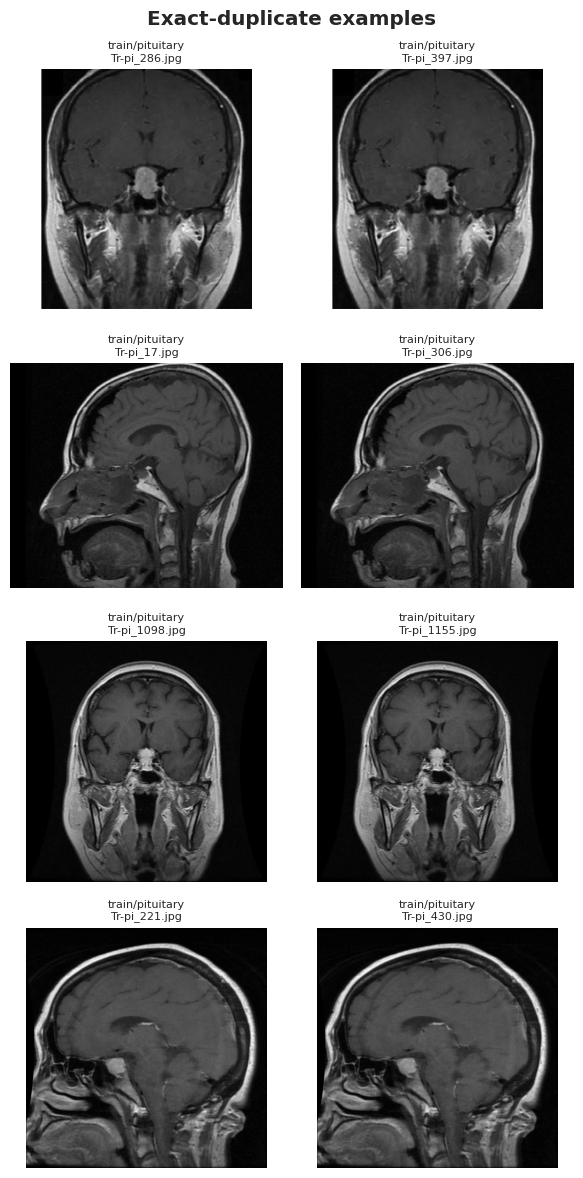

In [ ]:
# Visual proof: show a few duplicate groups (first two members of each)
dup_groups = [g for _, g in df[df['md5'].notna()].groupby('md5') if len(g) > 1][:4]
if dup_groups:
    fig, axes = plt.subplots(len(dup_groups), 2, figsize=(6, 3 * len(dup_groups)), squeeze=False)
    for r, g in enumerate(dup_groups):
        for c in range(2):
            row = g.iloc[c]
            axes[r][c].imshow(Image.open(row['path']).convert('L'), cmap='gray')
            axes[r][c].set_title(f"{row['split']}/{row['label']}\n{row['filename'][:22]}", fontsize=8)
            axes[r][c].axis('off')
    plt.suptitle('Exact-duplicate examples', fontweight='bold')
    plt.tight_layout()
    save_fig('01_duplicate_examples.png')
else:
    print("No exact duplicate groups found.")

### 4.4 Inconsistent formats
MRI datasets are usually assembled from many sources, so file types, colour modes and resolutions are often mixed. We inspect them on the files that survived so far.
Models need a **single uniform input** (same size, same channel layout), which we enforce in Section 7.

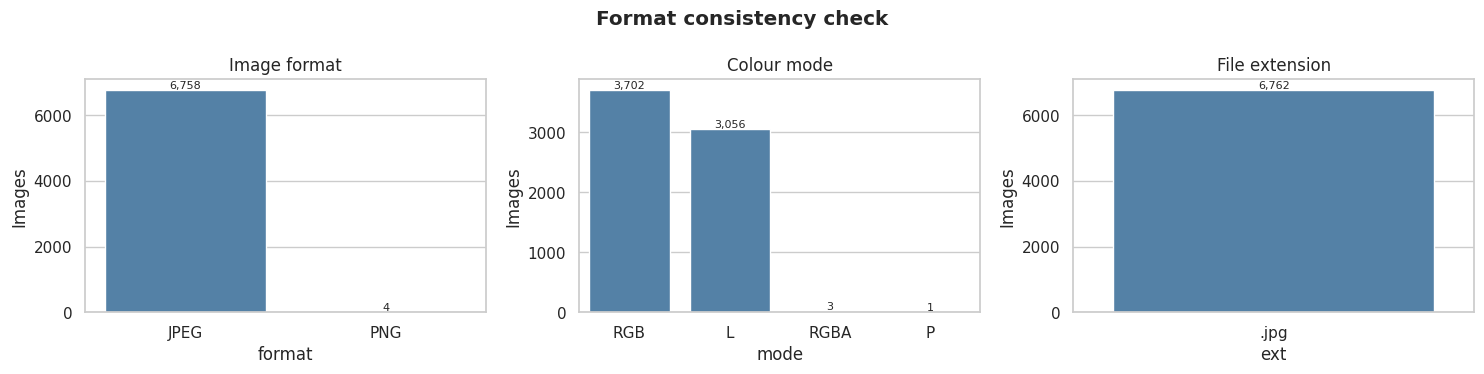

Distinct resolutions: 446
Colour files that are really greyscale: 3586 of 3705 RGB/RGBA files


,images
resolution,
512x512,4970
225x225,295
630x630,64
201x251,46
228x221,46
232x217,44
150x198,42
227x222,38
200x252,37


In [ ]:
ok = df[df['drop_reason'].isna()]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in zip(axes, ['format', 'mode', 'ext'], ['Image format', 'Colour mode', 'File extension']):
    vc = ok[col].value_counts()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, color='steelblue')
    ax.set_title(title); ax.set_ylabel('Images')
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
plt.suptitle('Format consistency check', fontweight='bold')
plt.tight_layout()
save_fig('02_format_consistency.png')

print("Distinct resolutions:", ok['resolution'].nunique())
print("Colour files that are really greyscale:", int(ok['gray_stored_as_rgb'].fillna(False).sum()),
      "of", int(ok['mode'].isin(['RGB', 'RGBA']).sum()), "RGB/RGBA files")
display(ok['resolution'].value_counts().head(10).rename('images').to_frame())

**Decision:** all images are converted to a single-channel (greyscale) representation and resized to 224×224 (padding to a square first so the anatomy is not stretched). MRI scans are intrinsically greyscale, so nothing is lost.

### 4.5 Outliers
We look for abnormal images using the **IQR rule** (below Q1−1.5·IQR or above Q3+1.5·IQR) on size, brightness, contrast, entropy, edge density and black-pixel fraction.

⚠️ **Policy:** unlike tabular data, an "outlier" MRI is often a *legitimate* scan (a different scanner, slice level or patient). Deleting these would remove real variation the model must learn to handle. So we **flag and inspect, but do not delete** — except truly blank/corrupt files already removed above.

In [ ]:
OUT_FEATS = ['width', 'height', 'aspect', 'file_kb', 'mean', 'std', 'entropy', 'edge_density', 'black_frac']
ok = df[df['drop_reason'].isna()].copy()

rows, flag = [], pd.DataFrame(index=ok.index)
for c in OUT_FEATS:
    q1, q3 = ok[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag[c] = (ok[c] < lo) | (ok[c] > hi)
    rows.append(dict(feature=c, lower_fence=lo, upper_fence=hi, n_outliers=int(flag[c].sum()),
                     pct=100 * flag[c].mean()))
display(pd.DataFrame(rows).round(3))

df.loc[ok.index, 'n_outlier_flags'] = flag.sum(axis=1)
print("Images flagged on ≥1 feature :", int((flag.sum(axis=1) >= 1).sum()))
print("Images flagged on ≥3 features:", int((flag.sum(axis=1) >= 3).sum()))

,feature,lower_fence,upper_fence,n_outliers,pct
0,width,512.000,512.000,1792,26.501
1,height,512.000,512.000,1788,26.442
2,aspect,1.000,1.000,1249,18.471
3,file_kb,0.157,42.453,161,2.381
4,mean,7.153,81.556,379,5.605
5,std,23.262,65.144,701,10.367
6,entropy,3.687,8.173,16,0.237
7,edge_density,0.236,13.147,1140,16.859
8,black_frac,-0.077,0.898,0,0.000


Images flagged on ≥1 feature : 1811
Images flagged on ≥3 features: 1671


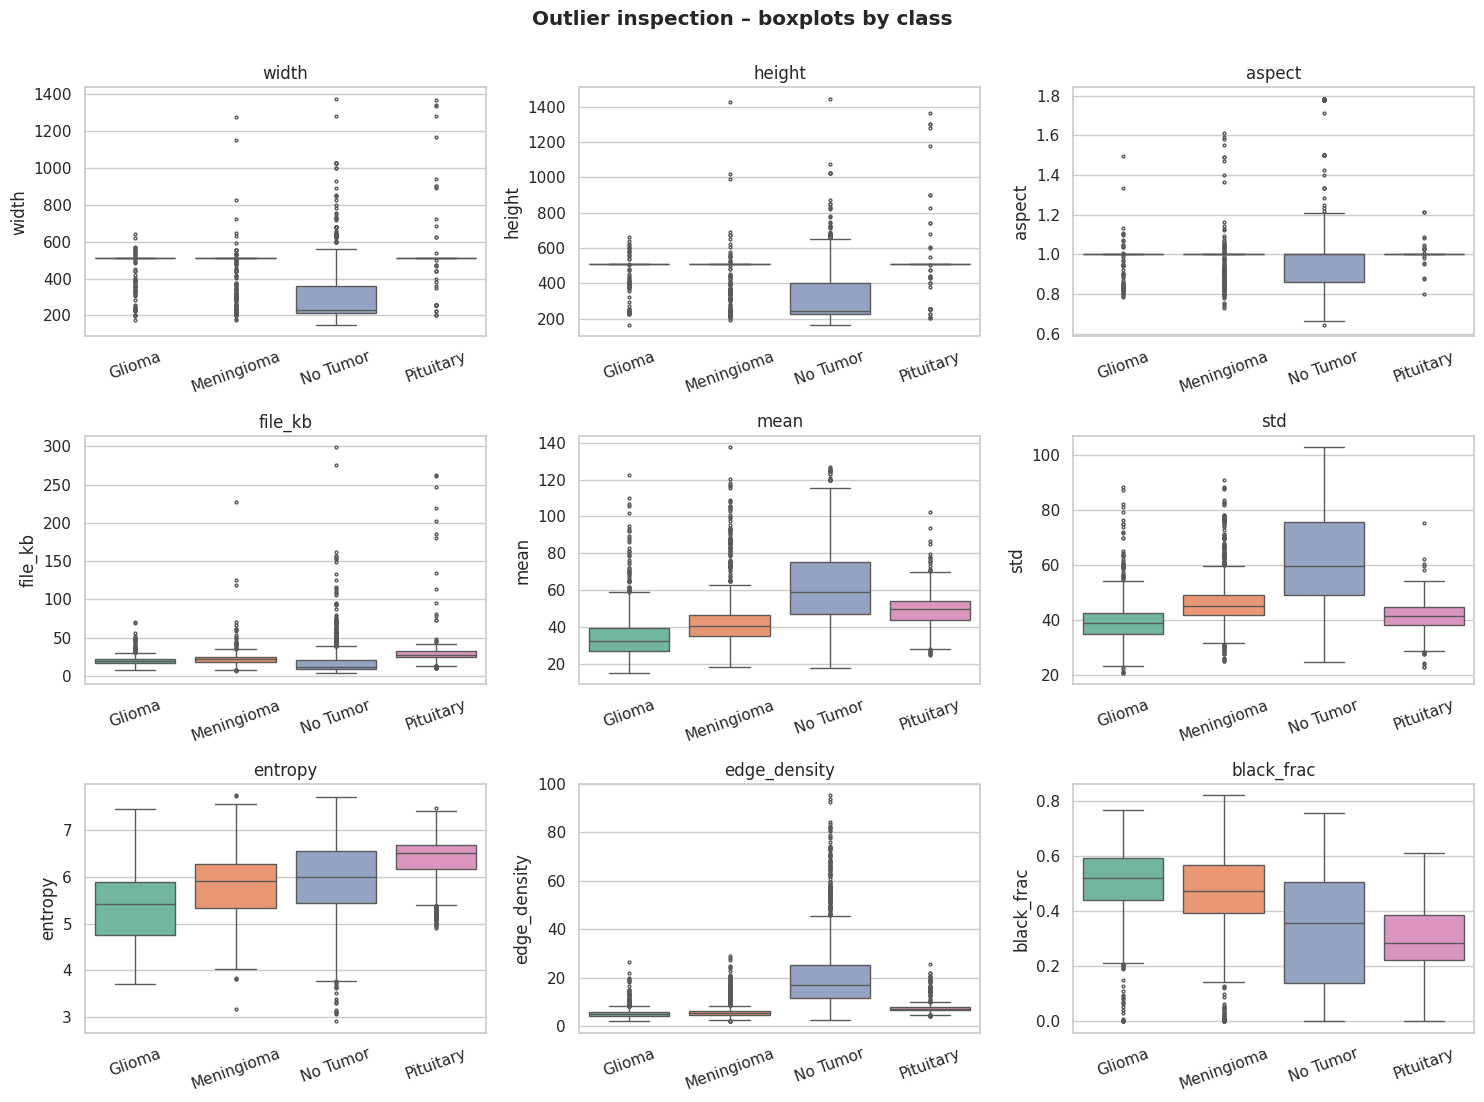

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), OUT_FEATS):
    sns.boxplot(data=ok, x='label', y=c, order=CLASS_NAMES, palette=PALETTE, ax=ax, fliersize=2)
    ax.set_xlabel(''); ax.set_title(c); ax.set_xticklabels([PRETTY[k] for k in CLASS_NAMES], rotation=20)
plt.suptitle('Outlier inspection – boxplots by class', fontweight='bold', y=1.0)
plt.tight_layout()
save_fig('03_outlier_boxplots.png')

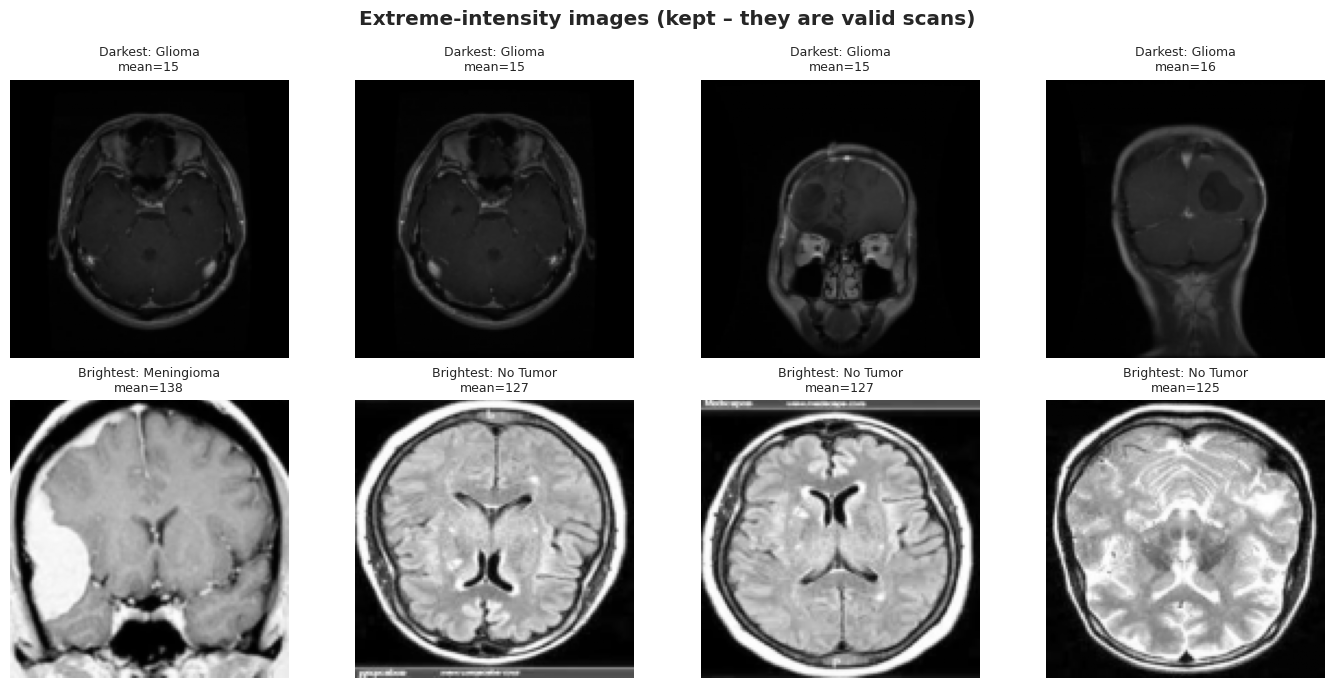

In [ ]:
# Look at the most extreme images (darkest / brightest mean intensity) before deciding
dark   = ok.nsmallest(4, 'mean')
bright = ok.nlargest(4, 'mean')
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax_row, subset, title in zip(axes, [dark, bright], ['Darkest', 'Brightest']):
    for ax, (_, r) in zip(ax_row, subset.iterrows()):
        ax.imshow(thumbs[r['orig_idx']], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{title}: {PRETTY[r['label']]}\nmean={r['mean']:.0f}", fontsize=9); ax.axis('off')
plt.suptitle('Extreme-intensity images (kept – they are valid scans)', fontweight='bold')
plt.tight_layout()
save_fig('04_extreme_images.png')

### 4.6 Apply the cleaning & save the log

In [ ]:
raw_n = len(df)
cleaning_log = df.loc[df['drop_reason'].notna(), ['path', 'split', 'label', 'md5', 'drop_reason']]
cleaning_log.to_csv(os.path.join(OUT_DATA, 'cleaning_log.csv'), index=False)

df_clean = df[df['drop_reason'].isna()].reset_index(drop=True)
thumbs_clean = thumbs[df_clean['orig_idx'].values]

print(f"Raw images     : {raw_n:,}")
print(f"Removed        : {len(cleaning_log):,}  ({100*len(cleaning_log)/raw_n:.2f}%)")
print(f"Clean images   : {len(df_clean):,}")

before = pd.crosstab(df['label'], df['split']).add_prefix('raw_')
after  = pd.crosstab(df_clean['label'], df_clean['split']).add_prefix('clean_')
display(pd.concat([before, after], axis=1))

Raw images     : 7,200
Removed        : 438  (6.08%)
Clean images   : 6,762


split,raw_test,raw_train,clean_test,clean_train
label,,,,
glioma,400,1400,383,1396
meningioma,400,1400,396,1287
notumor,400,1400,388,1154
pituitary,400,1400,400,1358


## 5. Exploratory Data Analysis
From here on we work only with the **cleaned** data (`df_clean`).

### 5.1 Class distribution & imbalance
Class balance decides which metrics (accuracy vs. macro-F1) and which tricks (class weights, resampling) we will need in Phase 2.

split,test,train,total,pct_of_total
label,,,,
glioma,383,1396,1779,26.31
meningioma,396,1287,1683,24.89
notumor,388,1154,1542,22.80
pituitary,400,1358,1758,26.00


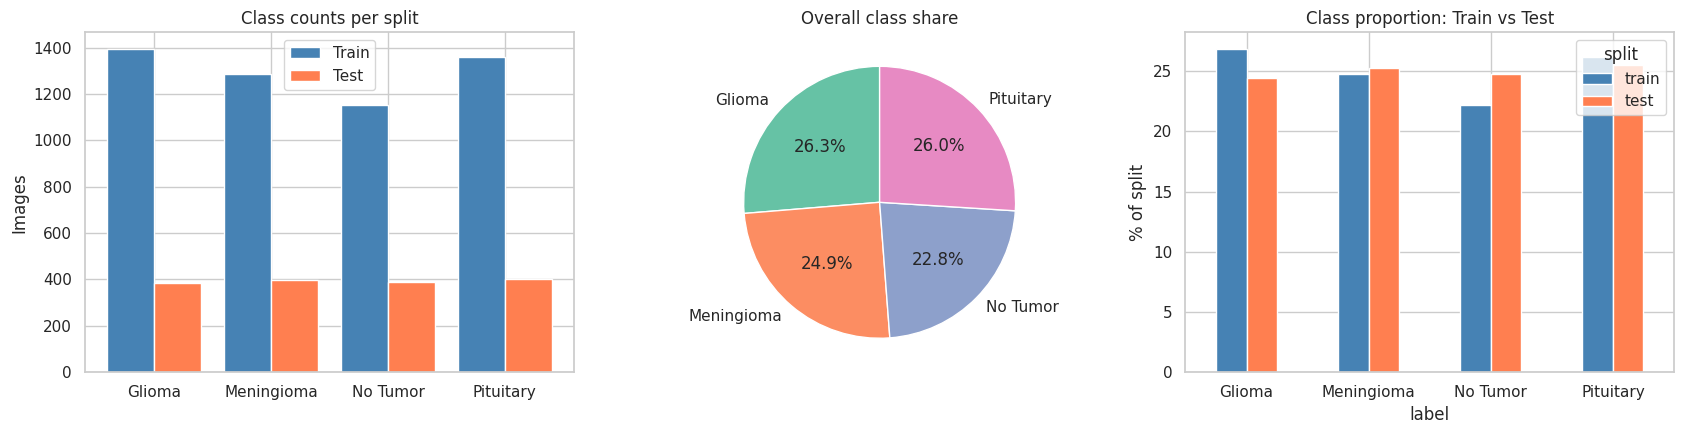

Imbalance ratio (largest/smallest train class): 1.21
Largest class: Glioma (1396) | Smallest: No Tumor (1154)


In [ ]:
ct = pd.crosstab(df_clean['label'], df_clean['split'])
ct['total'] = ct.sum(axis=1)
ct['pct_of_total'] = (100 * ct['total'] / ct['total'].sum()).round(2)
display(ct)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.arange(len(CLASS_NAMES))
axes[0].bar(x - 0.2, [ct.loc[c, 'train'] for c in CLASS_NAMES], 0.4, label='Train', color='steelblue')
axes[0].bar(x + 0.2, [ct.loc[c, 'test']  for c in CLASS_NAMES], 0.4, label='Test',  color='coral')
axes[0].set_xticks(x); axes[0].set_xticklabels([PRETTY[c] for c in CLASS_NAMES]); axes[0].set_ylabel('Images')
axes[0].set_title('Class counts per split'); axes[0].legend()

axes[1].pie(ct['total'], labels=[PRETTY[c] for c in CLASS_NAMES], autopct='%1.1f%%',
            colors=[PALETTE[c] for c in CLASS_NAMES], startangle=90)
axes[1].set_title('Overall class share')

prop = (ct[['train', 'test']] / ct[['train', 'test']].sum() * 100).loc[CLASS_NAMES]
prop.plot(kind='bar', ax=axes[2], color=['steelblue', 'coral'])
axes[2].set_xticklabels([PRETTY[c] for c in CLASS_NAMES], rotation=0)
axes[2].set_ylabel('% of split'); axes[2].set_title('Class proportion: Train vs Test')
plt.tight_layout()
save_fig('05_class_distribution.png')

tr_counts = ct.loc[CLASS_NAMES, 'train']
IMBALANCE_RATIO = tr_counts.max() / tr_counts.min()
print(f"Imbalance ratio (largest/smallest train class): {IMBALANCE_RATIO:.2f}")
print(f"Largest class: {PRETTY[tr_counts.idxmax()]} ({tr_counts.max()}) | Smallest: {PRETTY[tr_counts.idxmin()]} ({tr_counts.min()})")

**How to read this:** the left/right plots show whether Train and Test follow the same class proportions (they should, otherwise test metrics are not representative). The imbalance ratio tells us how skewed the classes are: close to 1 means balanced; above ~1.5 we should report macro-averaged metrics and consider class weights.

### 5.2 Sample images per class
Looking at the images tells us what the model will actually see — scan orientation (axial / sagittal / coronal), contrast, and how visible the tumours are.

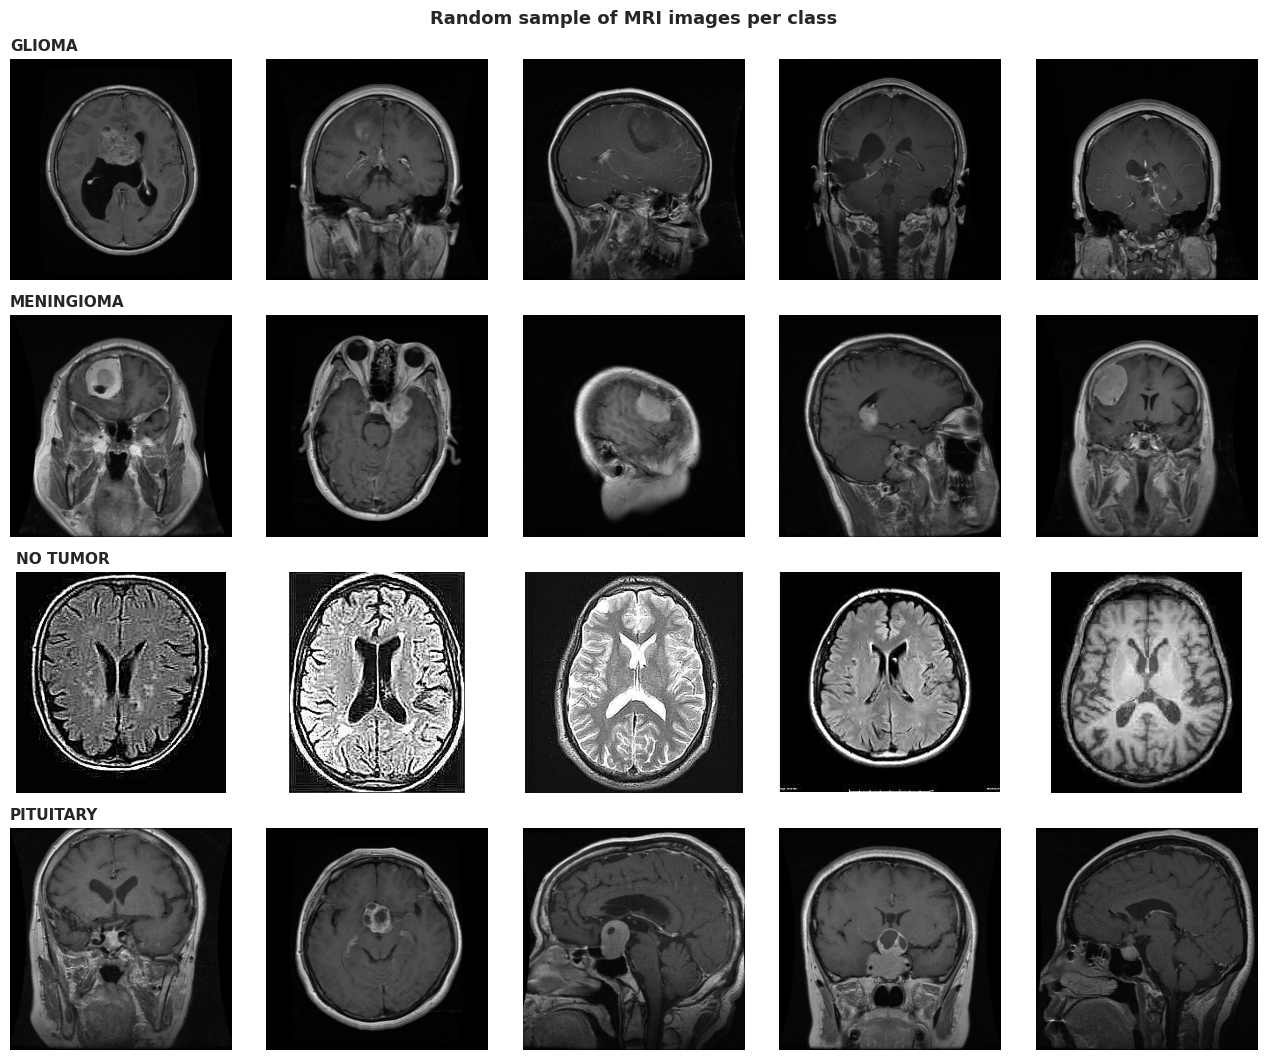

In [ ]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(13, 2.7 * len(CLASS_NAMES)))
rng = np.random.RandomState(SEED)
for r, cls in enumerate(CLASS_NAMES):
    idx = rng.choice(df_clean.index[df_clean['label'] == cls], 5, replace=False)
    for c, i in enumerate(idx):
        axes[r][c].imshow(Image.open(df_clean.loc[i, 'path']).convert('L'), cmap='gray')
        axes[r][c].axis('off')
    axes[r][0].set_title(PRETTY[cls].upper(), fontsize=11, fontweight='bold', loc='left')
plt.suptitle('Random sample of MRI images per class', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('06_sample_images.png')

### 5.3 Image dimensions & resolution
Images of different sizes must be resized. More importantly, if **resolution correlates with class**, a model could "cheat" by recognising the *source/scanner* instead of the tumour (a classic *shortcut* problem). We test for this with the contingency table and **Cramér's V** (0 = no association, 1 = perfect association).

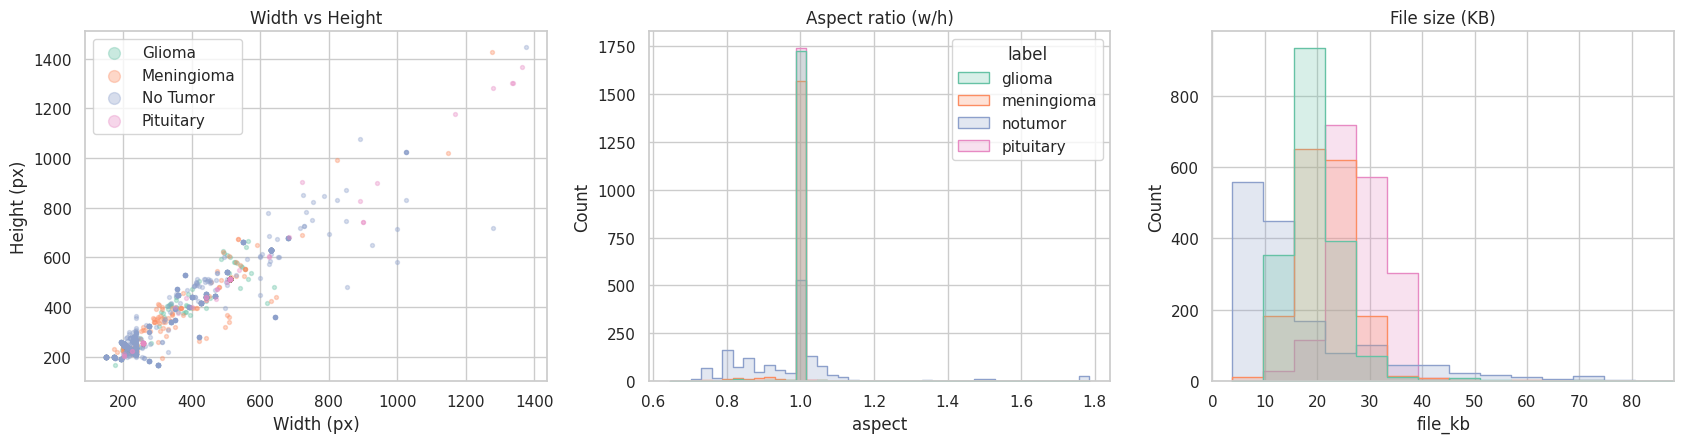

label,glioma,meningioma,notumor,pituitary
resolution,,,,
150x198,0,0,42,0
201x251,0,2,44,0
225x225,1,8,284,2
227x222,0,0,38,0
228x221,0,1,45,0
232x217,0,0,44,0
512x512,1714,1540,16,1700
630x630,0,0,64,0
other,64,132,965,56


label,glioma,meningioma,notumor,pituitary
% of class,,,,
150x198,0.0,0.0,2.7,0.0
201x251,0.0,0.1,2.9,0.0
225x225,0.1,0.5,18.4,0.1
227x222,0.0,0.0,2.5,0.0
228x221,0.0,0.1,2.9,0.0
232x217,0.0,0.0,2.9,0.0
512x512,96.3,91.5,1.0,96.7
630x630,0.0,0.0,4.2,0.0
other,3.6,7.8,62.6,3.2


Cramér's V (resolution vs class): 0.520


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for cls in CLASS_NAMES:
    s = df_clean[df_clean['label'] == cls]
    axes[0].scatter(s['width'], s['height'], s=8, alpha=0.35, label=PRETTY[cls], color=PALETTE[cls])
axes[0].set_xlabel('Width (px)'); axes[0].set_ylabel('Height (px)'); axes[0].set_title('Width vs Height'); axes[0].legend(markerscale=3)

sns.histplot(data=df_clean, x='aspect', hue='label', bins=40, ax=axes[1], palette=PALETTE, element='step')
axes[1].set_title('Aspect ratio (w/h)')

sns.histplot(data=df_clean, x='file_kb', hue='label', bins=50, ax=axes[2], palette=PALETTE, element='step', legend=False)
axes[2].set_title('File size (KB)'); axes[2].set_xlim(0, df_clean['file_kb'].quantile(0.995))
plt.tight_layout()
save_fig('07_dimensions.png')

top_res = df_clean['resolution'].value_counts().head(8).index
res_col = df_clean['resolution'].where(df_clean['resolution'].isin(top_res), 'other')
res_ct  = pd.crosstab(res_col, df_clean['label'])
display(res_ct)
display((res_ct / res_ct.sum() * 100).round(1).rename_axis('% of class'))

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
CRAMERS_RES = cramers_v(res_ct)
print(f"Cramér's V (resolution vs class): {CRAMERS_RES:.3f}")

### 5.4 Pixel-intensity & texture statistics by class
Do the classes differ in brightness, contrast or detail? Differences here show *what is learnable* even from simple statistics — and also warn of acquisition biases.

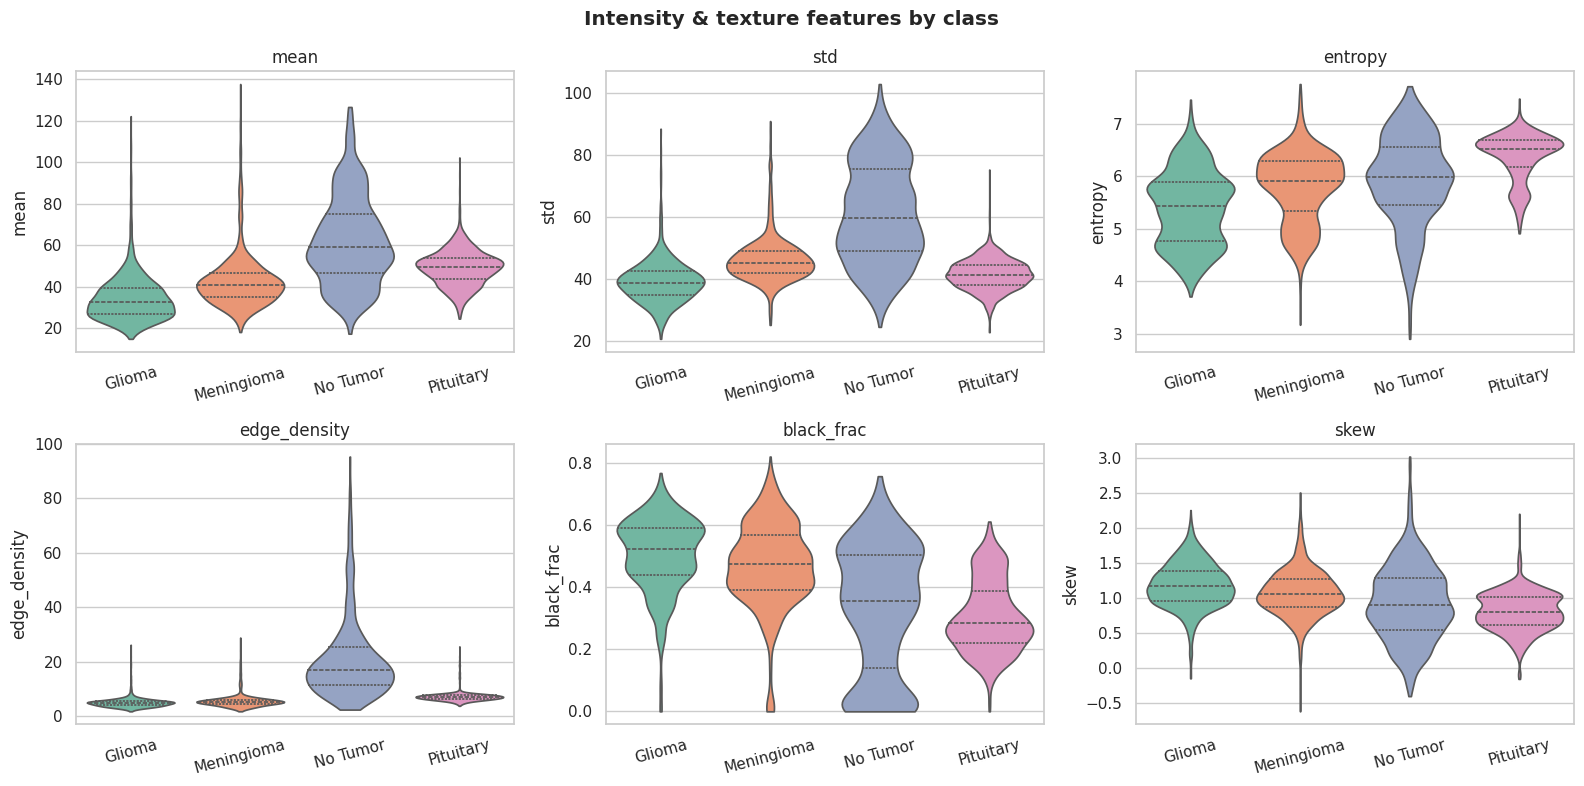

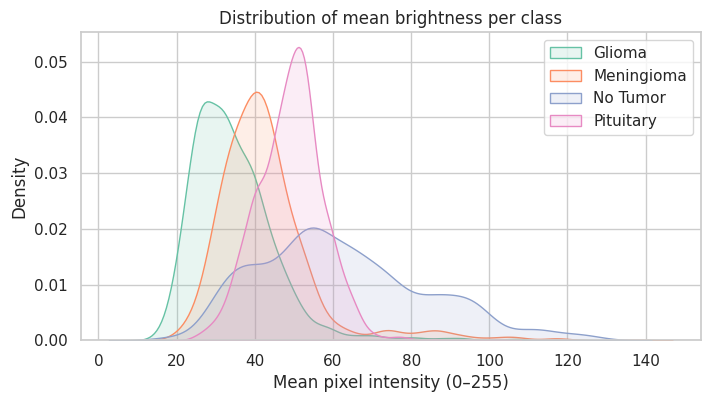

mean           std        entropy       edge_density         \
             mean    std   mean    std    mean   std         mean    std   
label                                                                      
glioma      34.53  11.17  39.19   6.97    5.39  0.71         5.11   1.80   
meningioma  42.90  13.38  46.32   7.51    5.80  0.66         5.81   2.74   
notumor     62.15  21.38  61.34  15.97    5.91  0.86        21.16  15.03   
pituitary   49.11   8.50  41.45   4.83    6.38  0.45         7.26   1.77   

           black_frac        skew         width          height          
                 mean   std  mean   std    mean     std    mean     std  
label                                                                    
glioma           0.50  0.12  1.18  0.32  507.16   34.35  508.12   31.83  
meningioma       0.47  0.14  1.07  0.33  497.22   68.24  498.42   66.13  
notumor          0.33  0.21  0.92  0.53  300.51  150.67  312.08  146.88  
pituitary        0.31  0.11  0.80  0.27  510.05   59.48  509.91   58.03

In [ ]:
feats6 = ['mean', 'std', 'entropy', 'edge_density', 'black_frac', 'skew']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), feats6):
    sns.violinplot(data=df_clean, x='label', y=c, order=CLASS_NAMES, palette=PALETTE, ax=ax, inner='quartile', cut=0)
    ax.set_xlabel(''); ax.set_title(c); ax.set_xticklabels([PRETTY[k] for k in CLASS_NAMES], rotation=15)
plt.suptitle('Intensity & texture features by class', fontweight='bold')
plt.tight_layout()
save_fig('08_intensity_violins.png')

fig, ax = plt.subplots(figsize=(8, 4))
for cls in CLASS_NAMES:
    sns.kdeplot(df_clean.loc[df_clean['label'] == cls, 'mean'], ax=ax, label=PRETTY[cls], color=PALETTE[cls], fill=True, alpha=0.15)
ax.set_xlabel('Mean pixel intensity (0–255)'); ax.set_title('Distribution of mean brightness per class'); ax.legend()
save_fig('09_mean_intensity_kde.png')

display(df_clean.groupby('label')[feats6 + ['width', 'height']].agg(['mean', 'std']).round(2))

### 5.5 Correlation analysis
The heatmap shows how the numeric image properties relate to each other. Strongly correlated features carry redundant information; features that are *constant* are dropped automatically.
The second heatmap shows each class's average feature value (z-scored per feature) — rows that differ in colour show which properties separate the classes.

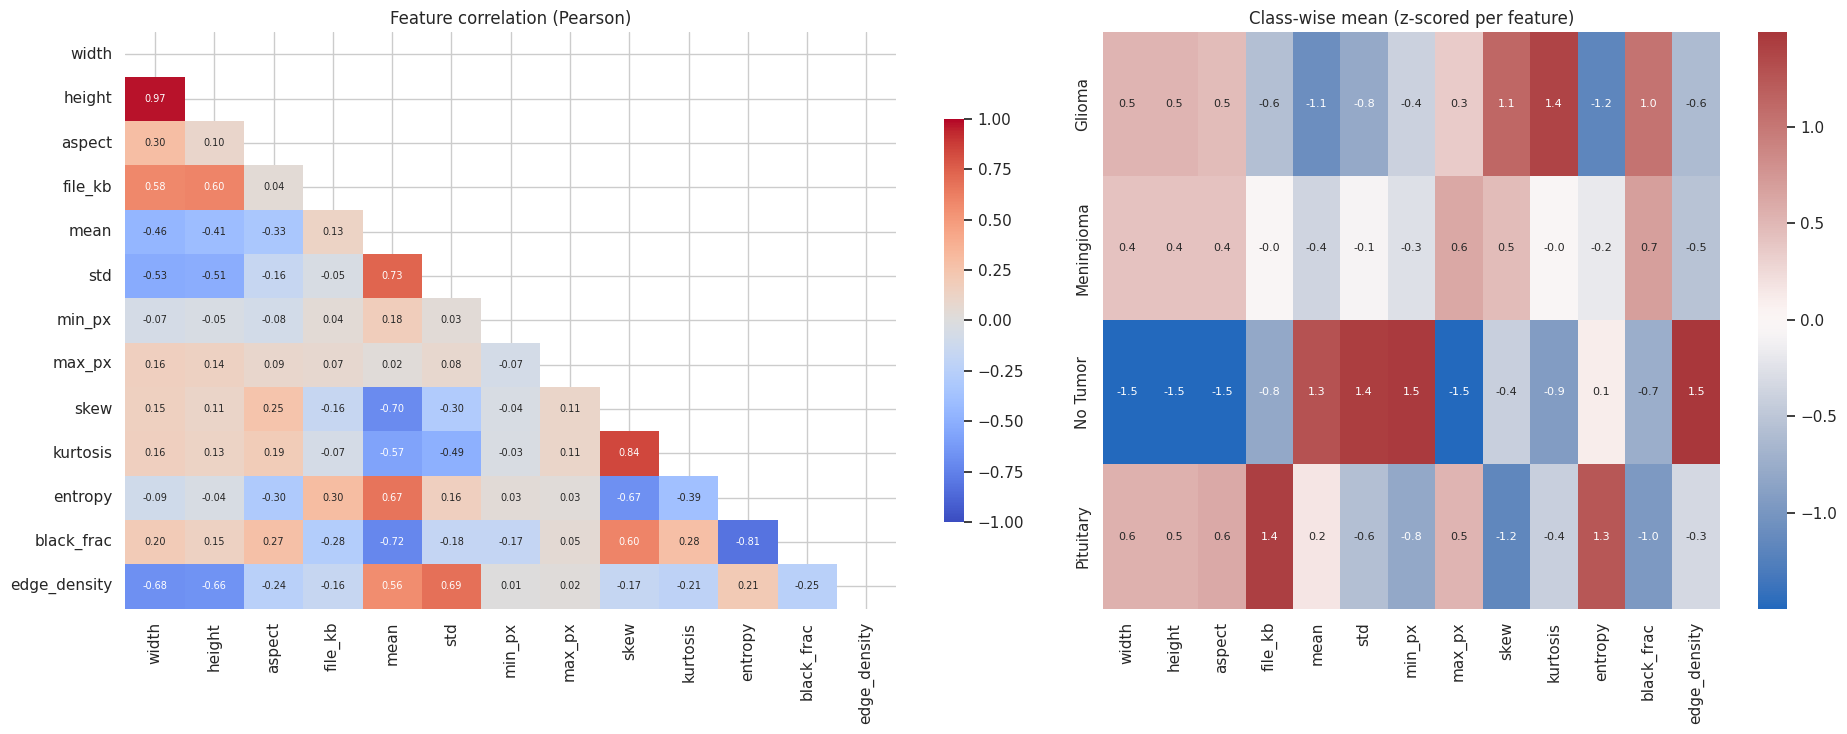

Highly correlated pairs (|r| ≥ 0.8):


,level_0,level_1,r
0,height,width,0.975
44,kurtosis,skew,0.837
65,black_frac,entropy,-0.814


In [ ]:
NUM_FEATS = ['width', 'height', 'aspect', 'file_kb', 'mean', 'std', 'min_px', 'max_px',
             'skew', 'kurtosis', 'entropy', 'black_frac', 'edge_density']
NUM_FEATS = [c for c in NUM_FEATS if df_clean[c].nunique() > 1]

corr = df_clean[NUM_FEATS].corr()
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={'width_ratios': [1.25, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'shrink': .7}, ax=axes[0])
axes[0].set_title('Feature correlation (Pearson)')

cm = df_clean.groupby('label')[NUM_FEATS].mean().loc[CLASS_NAMES]
cmz = (cm - cm.mean()) / cm.std().replace(0, 1)
cmz.index = [PRETTY[c] for c in cmz.index]
sns.heatmap(cmz, annot=True, fmt='.1f', cmap='vlag', center=0, annot_kws={'size': 8}, ax=axes[1])
axes[1].set_title('Class-wise mean (z-scored per feature)')
plt.tight_layout()
save_fig('10_correlation_heatmaps.png')

pairs = (corr.where(~mask).stack().rename('r').reset_index()
             .query('abs(r) >= 0.8').sort_values('r', key=abs, ascending=False))
print("Highly correlated pairs (|r| ≥ 0.8):")
display(pairs.round(3) if len(pairs) else "none")

### 5.6 Which features differ between classes? (statistical tests)
* **Kruskal–Wallis H-test:** non-parametric test of whether a feature's distribution differs across the 4 classes (small *p* ⇒ differs). Because we have thousands of images, *p* will almost always be tiny, so we also report the **effect size ε²** (≈0.01 small, 0.06 medium, 0.14+ large).
* **Mutual information (MI):** how much knowing the feature tells us about the class (0 = nothing).

,feature,H,p_value,epsilon_sq,mutual_info
0,edge_density,4019.2103,0.0,0.5943,0.5413
1,height,3324.2649,0.0,0.4915,0.4649
2,width,3640.0825,0.0,0.5382,0.4628
3,file_kb,2268.2263,0.0,0.3352,0.4157
4,std,2616.8498,0.0,0.3868,0.4060
5,mean,2573.8256,0.0,0.3804,0.3904
6,black_frac,1906.6785,0.0,0.2817,0.2793
7,aspect,447.1091,0.0,0.0657,0.2306
8,skew,1119.7246,0.0,0.1652,0.2303
9,kurtosis,601.2166,0.0,0.0885,0.2278


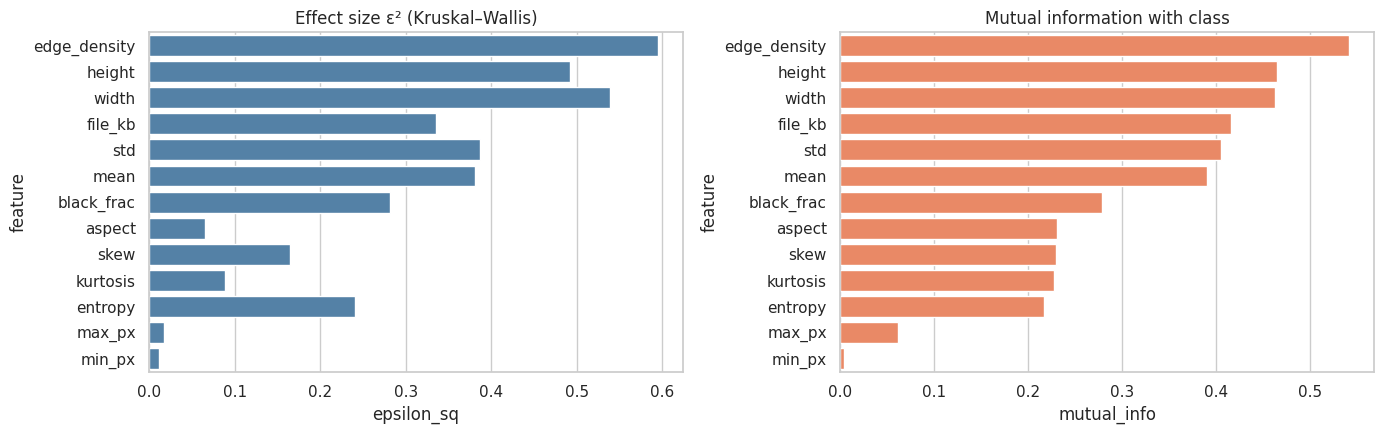

In [ ]:
kw = []
for c in NUM_FEATS:
    groups = [df_clean.loc[df_clean['label'] == k, c].dropna() for k in CLASS_NAMES]
    H, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    kw.append(dict(feature=c, H=H, p_value=p, epsilon_sq=(H - k + 1) / (n - k)))
kw = pd.DataFrame(kw)

X = df_clean[NUM_FEATS].fillna(df_clean[NUM_FEATS].median())
y = df_clean['label'].map({c: i for i, c in enumerate(CLASS_NAMES)})
kw['mutual_info'] = mutual_info_classif(X, y, random_state=SEED)
kw = kw.sort_values('mutual_info', ascending=False).reset_index(drop=True)
display(kw.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=kw, y='feature', x='epsilon_sq', ax=axes[0], color='steelblue'); axes[0].set_title('Effect size ε² (Kruskal–Wallis)')
sns.barplot(data=kw, y='feature', x='mutual_info', ax=axes[1], color='coral');   axes[1].set_title('Mutual information with class')
plt.tight_layout()
save_fig('11_feature_class_association.png')

### 5.7 Average image & pixel histograms per class
The **mean image** of a class shows where, on average, the brain and the tumour sit in the frame. The **difference** from the "No Tumor" mean highlights regions where tumour classes are systematically brighter (red) or darker (blue).
Pixel histograms exclude the black background (<10) so the tissue distribution is visible.

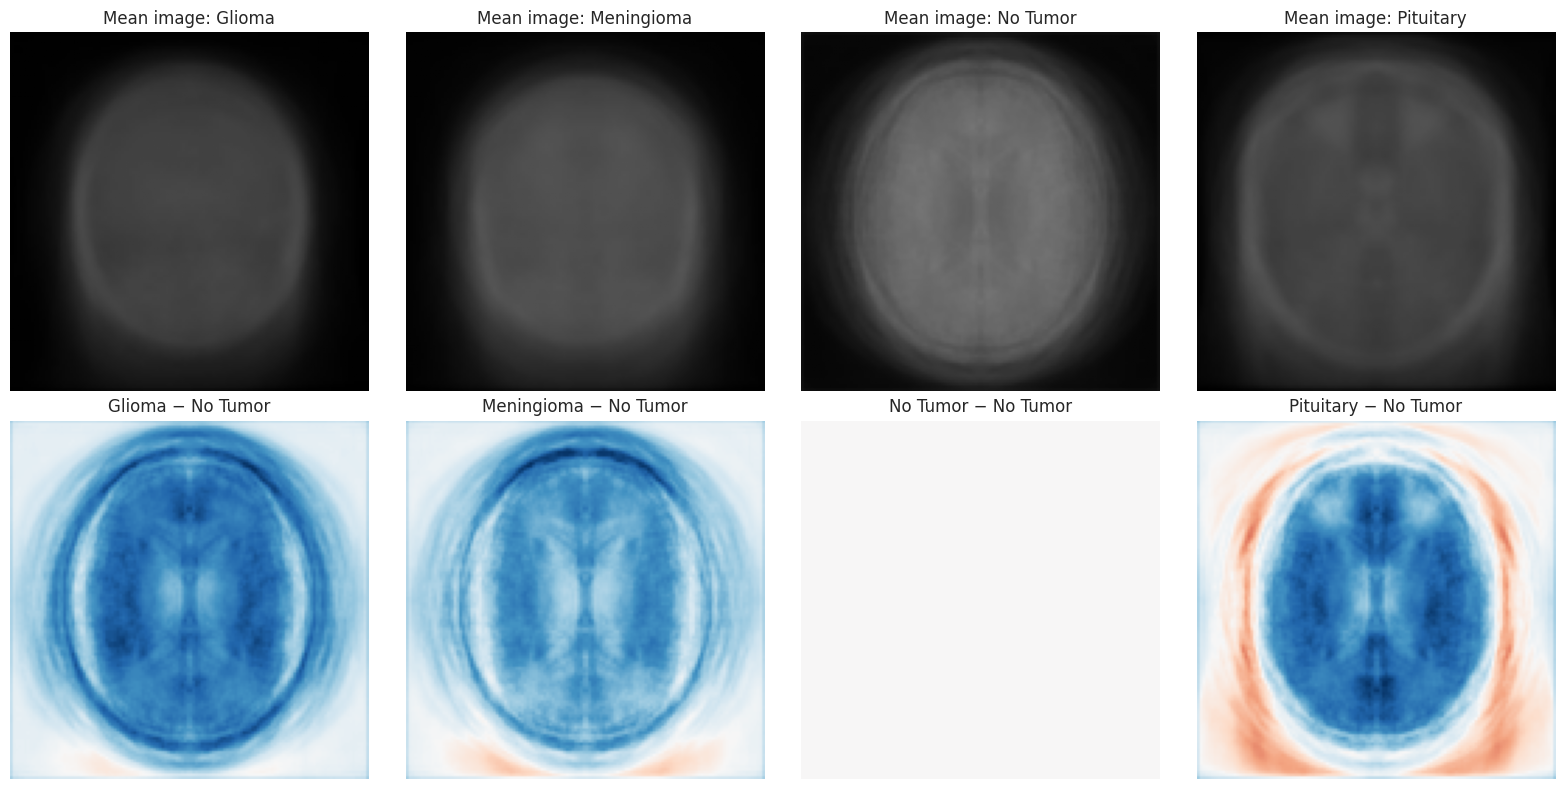

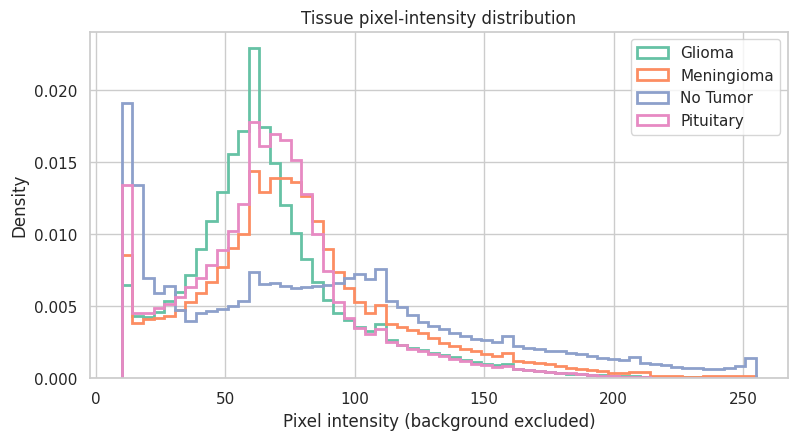

In [ ]:
mean_imgs = {c: thumbs_clean[(df_clean['label'] == c).values].astype(np.float32).mean(axis=0) for c in CLASS_NAMES}
ref = 'notumor' if 'notumor' in CLASS_NAMES else CLASS_NAMES[0]

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(4 * len(CLASS_NAMES), 8))
for j, c in enumerate(CLASS_NAMES):
    axes[0][j].imshow(mean_imgs[c], cmap='gray', vmin=0, vmax=255); axes[0][j].set_title(f'Mean image: {PRETTY[c]}'); axes[0][j].axis('off')
    d = mean_imgs[c] - mean_imgs[ref]
    lim = max(np.abs(d).max(), 1)
    im = axes[1][j].imshow(d, cmap='RdBu_r', vmin=-lim, vmax=lim); axes[1][j].set_title(f'{PRETTY[c]} − {PRETTY[ref]}'); axes[1][j].axis('off')
plt.tight_layout()
save_fig('12_mean_images.png')

fig, ax = plt.subplots(figsize=(9, 4.5))
rng = np.random.RandomState(SEED)
for c in CLASS_NAMES:
    idx = np.where((df_clean['label'] == c).values)[0]
    pix = thumbs_clean[rng.choice(idx, min(300, len(idx)), replace=False)].ravel()
    ax.hist(pix[pix >= 10], bins=60, range=(10, 255), density=True, histtype='step', linewidth=2, label=PRETTY[c], color=PALETTE[c])
ax.set_xlabel('Pixel intensity (background excluded)'); ax.set_ylabel('Density'); ax.set_title('Tissue pixel-intensity distribution'); ax.legend()
save_fig('13_pixel_histograms.png')

### 5.8 PCA — do the classes separate in raw pixel space?
We shrink each image to 32×32 and project onto the first two principal components. If classes form distinct clusters, even simple methods can separate them; heavy overlap suggests a deep model is needed.
The explained-variance curve shows how much redundancy there is in the pixels.

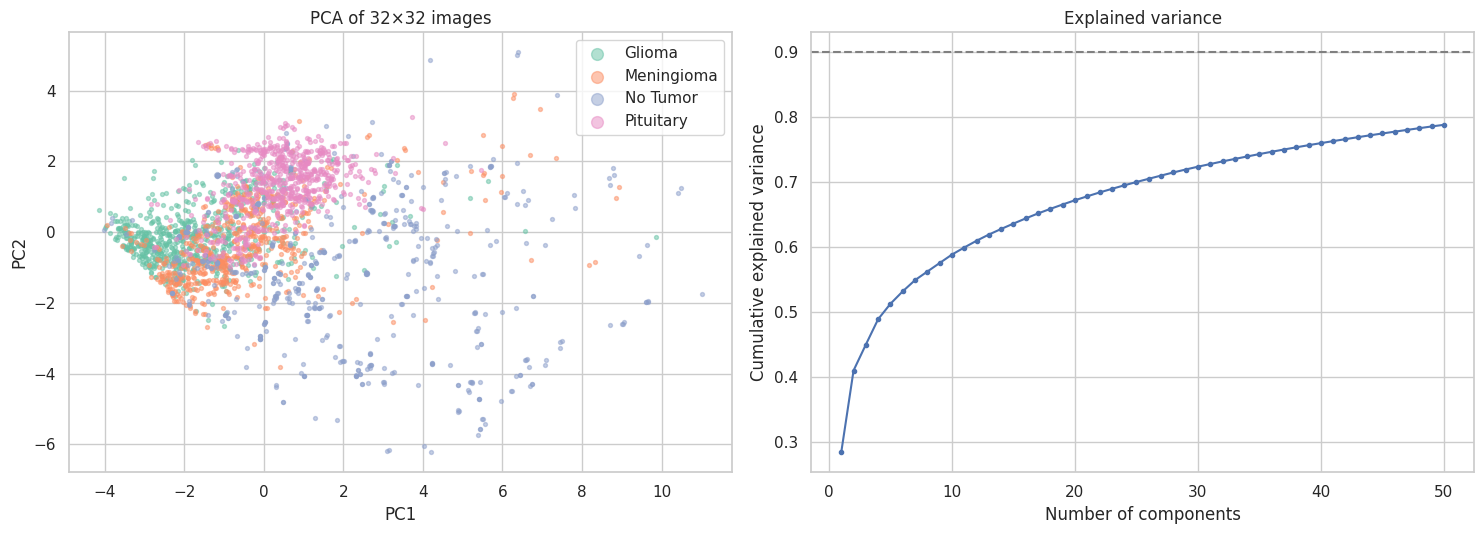

Components needed for 90% variance: >50


In [ ]:
rng = np.random.RandomState(SEED)
sel = rng.choice(len(df_clean), min(2500, len(df_clean)), replace=False)
small = thumbs_clean[sel].reshape(len(sel), 32, 4, 32, 4).mean(axis=(2, 4)).reshape(len(sel), -1) / 255.0
lab_sel = df_clean['label'].values[sel]

pca_full = PCA(n_components=min(50, small.shape[0] - 1), random_state=SEED).fit(small)
Z = PCA(n_components=2, random_state=SEED).fit_transform(small)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for c in CLASS_NAMES:
    m = lab_sel == c
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=PRETTY[c], color=PALETTE[c])
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2'); axes[0].set_title('PCA of 32×32 images'); axes[0].legend(markerscale=3)
cum = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].plot(range(1, len(cum) + 1), cum, marker='o', ms=3); axes[1].axhline(0.9, ls='--', color='gray')
axes[1].set_xlabel('Number of components'); axes[1].set_ylabel('Cumulative explained variance'); axes[1].set_title('Explained variance')
plt.tight_layout()
save_fig('14_pca.png')
N90 = int(np.argmax(cum >= 0.9) + 1) if (cum >= 0.9).any() else None
print("Components needed for 90% variance:", N90 if N90 else f">{len(cum)}")

### 5.9 Train vs Test distribution shift
Models are trained on the Training folder but judged on the Testing folder. If the two differ in brightness, size or contrast, test performance will drop for reasons unrelated to model quality.
We compare them with the two-sample **Kolmogorov–Smirnov test** (statistic = largest gap between the distributions; 0 = identical).

,feature,train_mean,test_mean,KS_stat,p_value
0,width,464.8716,436.5705,0.1166,0.0000
1,height,468.0391,439.6739,0.1201,0.0000
2,mean,45.8218,49.6261,0.0995,0.0000
3,std,46.0706,48.3770,0.1048,0.0000
4,entropy,5.8554,5.9140,0.0449,0.0151
5,edge_density,9.4872,9.5520,0.1173,0.0000


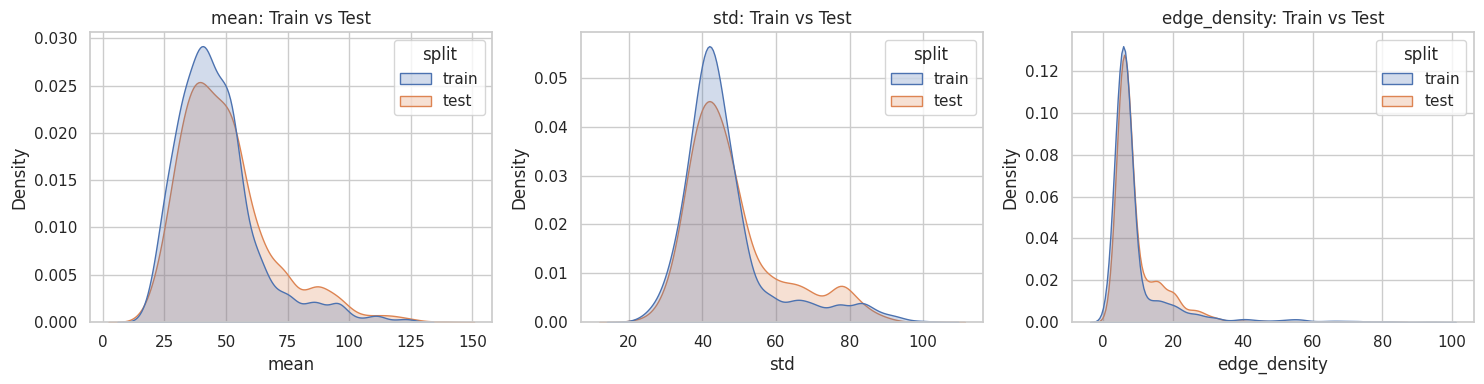

In [ ]:
rows = []
for c in ['width', 'height', 'mean', 'std', 'entropy', 'edge_density']:
    a = df_clean.loc[df_clean['split'] == 'train', c].dropna(); b = df_clean.loc[df_clean['split'] == 'test', c].dropna()
    ks = stats.ks_2samp(a, b)
    rows.append(dict(feature=c, train_mean=a.mean(), test_mean=b.mean(), KS_stat=ks.statistic, p_value=ks.pvalue))
shift = pd.DataFrame(rows)
display(shift.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['mean', 'std', 'edge_density']):
    sns.kdeplot(data=df_clean, x=c, hue='split', common_norm=False, fill=True, alpha=0.25, ax=ax)
    ax.set_title(f'{c}: Train vs Test')
plt.tight_layout()
save_fig('15_train_test_shift.png')

## 6. Insights
The cell below turns the numbers computed above into a written summary, so the statements always match the data currently loaded.
Use it as the basis for the *Key Findings* section of your README.

In [ ]:
top_feats = kw.head(3)
shift_flag = shift[(shift['KS_stat'] > 0.1)]
n_total_out = int((df['n_outlier_flags'] >= 1).sum())
reasons = cleaning_log['drop_reason'].value_counts()

lines = []
lines.append(f"DATASET: {raw_n:,} raw images → {len(df_clean):,} after cleaning ({len(cleaning_log):,} removed, {100*len(cleaning_log)/raw_n:.2f}%).")
if len(cleaning_log):
    lines.append("CLEANING: " + "; ".join(f"{v} × {k}" for k, v in reasons.items()) + ".")
else:
    lines.append("CLEANING: no corrupt, blank or duplicate files were found.")
leak = int(reasons.filter(like='leakage').sum()) if len(reasons) else 0
lines.append(f"LEAKAGE: {leak} training images were also present in the test set and were removed from training." if leak else "LEAKAGE: no training image was found in the test set.")

lines.append(f"CLASS BALANCE: imbalance ratio = {IMBALANCE_RATIO:.2f} "
             f"(largest: {PRETTY[tr_counts.idxmax()]}, smallest: {PRETTY[tr_counts.idxmin()]}). "
             + ("Classes are roughly balanced; accuracy is a usable metric but we will still report macro-F1." if IMBALANCE_RATIO < 1.5
                else "Noticeable imbalance → use class weights and macro-averaged metrics."))
lines.append(f"FORMATS: {df_clean['resolution'].nunique()} distinct resolutions; most common is {df_clean['resolution'].value_counts().index[0]} "
             f"({100*df_clean['resolution'].value_counts().iloc[0]/len(df_clean):.1f}% of images). Colour modes: {', '.join(df_clean['mode'].value_counts().index.astype(str))}. "
             "All images will be converted to padded-square greyscale 224×224.")
lines.append(f"SHORTCUT RISK: Cramér's V between resolution and class = {CRAMERS_RES:.2f} "
             + ("(strong association – resolution leaks the label; consider resizing aggressively and checking the model does not rely on it)." if CRAMERS_RES > 0.3
                else "(weak/moderate association – resolution is not a strong shortcut)."))
lines.append("MOST CLASS-INFORMATIVE SIMPLE FEATURES: " + ", ".join(f"{r.feature} (MI={r.mutual_info:.3f}, ε²={r.epsilon_sq:.3f})" for r in top_feats.itertuples()) + ".")
lines.append(f"OUTLIERS: {n_total_out:,} images ({100*n_total_out/len(df_clean):.1f}%) flagged on ≥1 feature by the IQR rule; they were kept because they are valid scans.")
lines.append(f"REDUNDANCY: {len(pairs)} feature pairs have |r| ≥ 0.8 (e.g. {pairs.iloc[0]['level_0']} & {pairs.iloc[0]['level_1']}, r={pairs.iloc[0]['r']:.2f})." if len(pairs) else "REDUNDANCY: no strongly correlated feature pairs.")
lines.append(f"PCA: {N90 if N90 else '>50'} components explain 90% of the pixel variance (of 1,024 pixels) – the images are highly redundant/structured.")
lines.append("TRAIN/TEST SHIFT: " + (", ".join(f"{r.feature} (KS={r.KS_stat:.2f})" for r in shift_flag.itertuples()) + " differ noticeably between Train and Test." if len(shift_flag)
             else "Train and Test distributions are similar on all checked features (KS < 0.1)."))

print("=" * 100)
for l in lines:
    print("•", l, "\n")

• DATASET: 7,200 raw images → 6,762 after cleaning (438 removed, 6.08%). 

• CLEANING: 187 × exact duplicate: duplicate; 161 × near duplicate: train/test leakage; 90 × near duplicate: duplicate. 

• LEAKAGE: 161 training images were also present in the test set and were removed from training. 

• CLASS BALANCE: imbalance ratio = 1.21 (largest: Glioma, smallest: No Tumor). Classes are roughly balanced; accuracy is a usable metric but we will still report macro-F1. 

• FORMATS: 446 distinct resolutions; most common is 512x512 (73.5% of images). Colour modes: RGB, L, RGBA, P. All images will be converted to padded-square greyscale 224×224. 

• SHORTCUT RISK: Cramér's V between resolution and class = 0.52 (strong association – resolution leaks the label; consider resizing aggressively and checking the model does not rely on it). 

• MOST CLASS-INFORMATIVE SIMPLE FEATURES: edge_density (MI=0.541, ε²=0.594), height (MI=0.465, ε²=0.491), width (MI=0.463, ε²=0.538). 

• OUTLIERS: 1,811 images 

### Implications for Phase 2 (modelling)
* **Metrics:** report accuracy *and* macro precision / recall / F1 and a confusion matrix (clinically, missing a tumour is worse than a false alarm).
* **Imbalance:** use the class weights saved in Section 7 if the imbalance ratio above is noticeable.
* **Input pipeline:** use the cleaned 224×224 images; replicate the single grey channel to 3 channels for ImageNet-pretrained backbones.
* **Augmentation:** mild flips, small rotations, zoom and shifts are appropriate for MRI; avoid augmentations that alter anatomy unrealistically (e.g. strong colour jitter).
* **Validation:** use the stratified validation split created below — never tune on the Testing folder.
* **Shortcut check:** if resolution / brightness are strongly tied to class, verify later (e.g. Grad-CAM) that the model looks at the tumour, not the image borders.

## 7. Preprocessing, Normalisation & Scaling
Steps:
1. **Stratified train/validation split** of the cleaned Training data (the Testing folder stays as the untouched test set).
2. **Pad to square (black) → resize to 224×224 → greyscale** so every image has identical shape without distortion. Saved as PNG (lossless) in `processed_data/`.
3. **Pixel scaling:** divide by 255 → values in [0, 1].
4. **Standardisation:** subtract the training-set mean and divide by the training-set std. Statistics are computed on the **training split only**, so no information from validation/test leaks into preprocessing.
5. **Class weights** computed from the training split.
6. Save the **manifest**, **cleaned metadata** and **preprocessing statistics** so Phase 2 can load everything directly.

In [ ]:
# 1) Stratified split
df_clean['final_split'] = 'test'
tr = df_clean[df_clean['split'] == 'train']
tr_idx, va_idx = train_test_split(tr.index, test_size=VAL_SPLIT, stratify=tr['label'], random_state=SEED)
df_clean.loc[tr_idx, 'final_split'] = 'train'
df_clean.loc[va_idx, 'final_split'] = 'val'

split_ct = pd.crosstab(df_clean['label'], df_clean['final_split'])[['train', 'val', 'test']]
display(split_ct)
display((split_ct / split_ct.sum() * 100).round(1).rename_axis('% of split'))

final_split,train,val,test
label,,,
glioma,1117,279,383
meningioma,1030,257,396
notumor,923,231,388
pituitary,1086,272,400


final_split,train,val,test
% of split,,,
glioma,26.9,26.9,24.4
meningioma,24.8,24.7,25.3
notumor,22.2,22.2,24.8
pituitary,26.1,26.2,25.5


In [ ]:
# 2) Pad → resize → greyscale → save
def pad_to_square(img, fill=0):
    w, h = img.size; s = max(w, h)
    canvas = Image.new('L', (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

def preprocess(path):
    img = Image.open(path).convert('L')
    return pad_to_square(img).resize(IMG_SIZE, Image.LANCZOS)

proc_paths = []
for i, r in tqdm(df_clean.iterrows(), total=len(df_clean), desc='Preprocessing'):
    out_dir = os.path.join(PROC_DIR, r['final_split'], r['label'])
    os.makedirs(out_dir, exist_ok=True)
    out = os.path.join(out_dir, f"{i:05d}_{os.path.splitext(r['filename'])[0]}.png")
    preprocess(r['path']).save(out)
    proc_paths.append(out)
df_clean['processed_path'] = proc_paths
print(f"✅ Saved {len(proc_paths):,} processed images to '{PROC_DIR}/'")

Preprocessing:   0%|          | 0/6762 [00:00<?, ?it/s]

✅ Saved 6,762 processed images to 'processed_data/'


In [ ]:
# Verification: every processed image must have identical shape/dtype
rng = np.random.RandomState(SEED)
check = rng.choice(len(df_clean), min(300, len(df_clean)), replace=False)
shapes = {np.asarray(Image.open(df_clean.loc[i, 'processed_path'])).shape for i in check}
print("Unique processed shapes in a 300-image check:", shapes)
assert shapes == {IMG_SIZE}, "Processed images do not all have the expected size!"
assert df_clean['processed_path'].map(os.path.exists).all(), "Some processed files are missing!"
print(" All checks passed")

Unique processed shapes in a 300-image check: {(224, 224)}
 All checks passed


In [ ]:
# 3 + 4) Scaling statistics computed on the TRAINING split only (streaming, no big array in memory)
n_pix, s1, s2 = 0, 0.0, 0.0
for p in tqdm(df_clean.loc[df_clean['final_split'] == 'train', 'processed_path'], desc='Train mean/std'):
    a = np.asarray(Image.open(p), dtype=np.float64) / 255.0
    n_pix += a.size; s1 += a.sum(); s2 += (a ** 2).sum()
TRAIN_MEAN = s1 / n_pix
TRAIN_STD  = np.sqrt(s2 / n_pix - TRAIN_MEAN ** 2)
print(f"Training-set pixel mean = {TRAIN_MEAN:.4f} | std = {TRAIN_STD:.4f}   (on the 0–1 scale)")

Train mean/std:   0%|          | 0/4156 [00:00<?, ?it/s]

Training-set pixel mean = 0.1749 | std = 0.1953   (on the 0–1 scale)


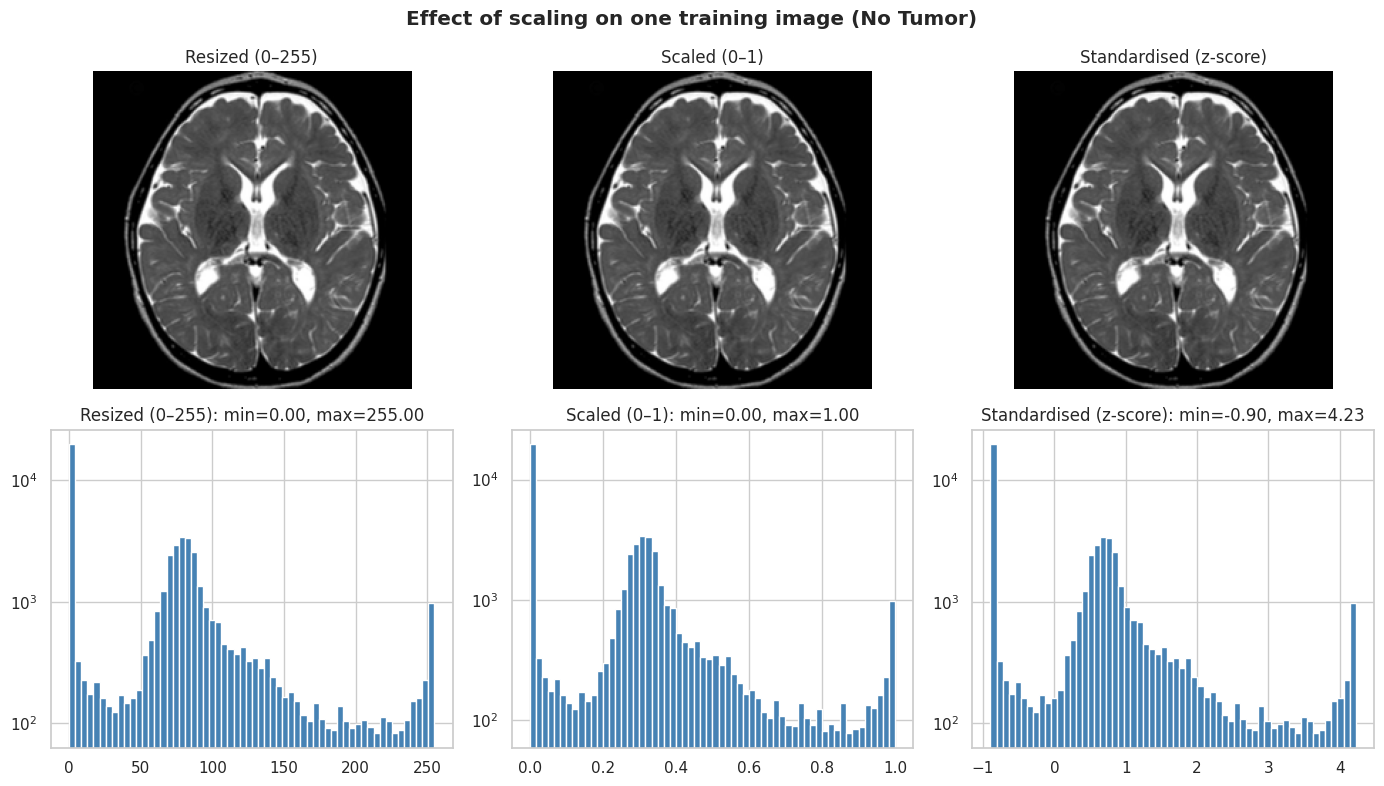

Sample (n=200) BEFORE scaling : mean=45.09, std=51.07, range=[0, 255]
Sample (n=200) AFTER  scaling : mean=0.010, std=1.026, range=[-0.90, 4.23]


In [ ]:
# Before / after scaling on one training image + a 200-image sample
s = df_clean[df_clean['final_split'] == 'train'].sample(1, random_state=SEED).iloc[0]
raw_arr    = np.asarray(Image.open(s['processed_path']), dtype=np.float32)      # 0–255
scaled     = raw_arr / 255.0                                                     # 0–1
standard   = (scaled - TRAIN_MEAN) / TRAIN_STD                                   # z-score

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, (arr, name) in enumerate([(raw_arr, 'Resized (0–255)'), (scaled, 'Scaled (0–1)'), (standard, 'Standardised (z-score)')]):
    axes[0][j].imshow(arr, cmap='gray'); axes[0][j].set_title(name); axes[0][j].axis('off')
    axes[1][j].hist(arr.ravel(), bins=60, color='steelblue'); axes[1][j].set_title(f'{name}: min={arr.min():.2f}, max={arr.max():.2f}')
    axes[1][j].set_yscale('log')
plt.suptitle(f"Effect of scaling on one training image ({PRETTY[s['label']]})", fontweight='bold')
plt.tight_layout()
save_fig('16_scaling_before_after.png')

samp = df_clean[df_clean['final_split'] == 'train'].sample(min(200, (df_clean['final_split'] == 'train').sum()), random_state=SEED)
arr = np.stack([np.asarray(Image.open(p), dtype=np.float32) for p in samp['processed_path']])
print(f"Sample (n={len(samp)}) BEFORE scaling : mean={arr.mean():.2f}, std={arr.std():.2f}, range=[{arr.min():.0f}, {arr.max():.0f}]")
z = ((arr / 255.0) - TRAIN_MEAN) / TRAIN_STD
print(f"Sample (n={len(samp)}) AFTER  scaling : mean={z.mean():.3f}, std={z.std():.3f}, range=[{z.min():.2f}, {z.max():.2f}]")

**Why this matters:** neural networks train faster and more stably when inputs are small and centred around zero. After standardisation the sample's mean is ≈0 and std ≈1. The log-scale histogram shows the shape of the intensity distribution is preserved — only its range changes.

In [ ]:
# 5) Class weights (from training split) – 'balanced' = n / (k * count_c)
train_labels = df_clean.loc[df_clean['final_split'] == 'train', 'label']
cw = compute_class_weight('balanced', classes=np.array(CLASS_NAMES), y=train_labels)
class_weights = {i: float(w) for i, w in enumerate(cw)}
display(pd.DataFrame({'class': [PRETTY[c] for c in CLASS_NAMES], 'index': range(len(CLASS_NAMES)),
                      'train_count': [int((train_labels == c).sum()) for c in CLASS_NAMES], 'class_weight': cw.round(4)}))

,class,index,train_count,class_weight
0,Glioma,0,1117,0.9302
1,Meningioma,1,1030,1.0087
2,No Tumor,2,923,1.1257
3,Pituitary,3,1086,0.9567


In [ ]:
# 6) Save everything Phase 2 needs
manifest = df_clean[['processed_path', 'label', 'final_split', 'path', 'split']].rename(columns={'path': 'original_path', 'split': 'original_split'})
manifest['label_idx'] = manifest['label'].map({c: i for i, c in enumerate(CLASS_NAMES)})
manifest.to_csv(os.path.join(OUT_DATA, 'cleaned_manifest.csv'), index=False)

keep_cols = [c for c in df_clean.columns if c not in ('orig_idx', 'error', 'drop_reason')]
df_clean[keep_cols].to_csv(os.path.join(OUT_DATA, 'cleaned_metadata.csv'), index=False)

prep_stats = dict(img_size=list(IMG_SIZE), channels=1, pixel_scale='divide by 255', train_mean=TRAIN_MEAN, train_std=TRAIN_STD,
                  classes=CLASS_NAMES, class_to_idx={c: i for i, c in enumerate(CLASS_NAMES)}, class_weights=class_weights,
                  val_split=VAL_SPLIT, seed=SEED, n_raw=raw_n, n_clean=len(df_clean),
                  counts=split_ct.to_dict())
with open(os.path.join(OUT_DATA, 'preprocessing_stats.json'), 'w') as f:
    json.dump(prep_stats, f, indent=2)

print("Saved:")
for f in sorted(os.listdir(OUT_DATA)):
    print("  data/" + f)
print(f"  {len(os.listdir(OUT_IMG))} figures in images/")

Saved:
  data/cleaned_manifest.csv
  data/cleaned_metadata.csv
  data/cleaning_log.csv
  data/preprocessing_stats.json
  16 figures in images/


## 8. Phase 1 Summary
| Item | Status |
|------|--------|
| Missing / corrupt files | Detected, logged and removed (`data/cleaning_log.csv`) |
| Duplicates & train↔test leakage | Exact (md5) + near-duplicate (dHash) detection, removed per policy in 4.3 |
| Outliers | Flagged via IQR, inspected visually, retained (valid scans) |
| Inconsistent formats | Standardised to padded-square greyscale 224×224 PNG |
| EDA | Class balance, sizes, intensity/texture, correlation, statistical tests, mean images, PCA, train/test shift |
| Insights | Section 6 (auto-generated from the data) |
| Scaling | Pixels ÷ 255 and z-score using training-set mean/std (`data/preprocessing_stats.json`) |
| Outputs | `processed_data/`, `data/cleaned_manifest.csv`, `data/cleaned_metadata.csv`, `images/*.png` |

**Next (Phase 2):** load `data/cleaned_manifest.csv`, build the input pipeline from `processed_data/`, and train / evaluate the models.